# Notebook to create Figure S1

In [1]:
library(ggplot2)
library(readr)
library(glue)
library(tidyverse)
library(RColorBrewer)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ stringr   1.5.2
✔ forcats   1.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.1.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [2]:
path <- glue("../../Data/ANI/")

In [3]:
models <- c("dnaberts", "dnabert2", "hyenadna", "tnf", "dna2vec")

df_all <- map_dfr(models, function(model) {
  read_csv(glue("{path}/ani_vs_emb_{model}.csv"), show_col_types = FALSE) %>%
    mutate(model = model)
}) %>%
  mutate(model = factor(model, levels = models))

In [4]:
model_labels <- c(
  dnaberts  = "DNABERT-S",
  dnabert2  = "DNABERT-2",
  hyenadna  = "HyenaDNA",
  tnf  = "TNF",
  dna2vec   = "dna2vec"
)

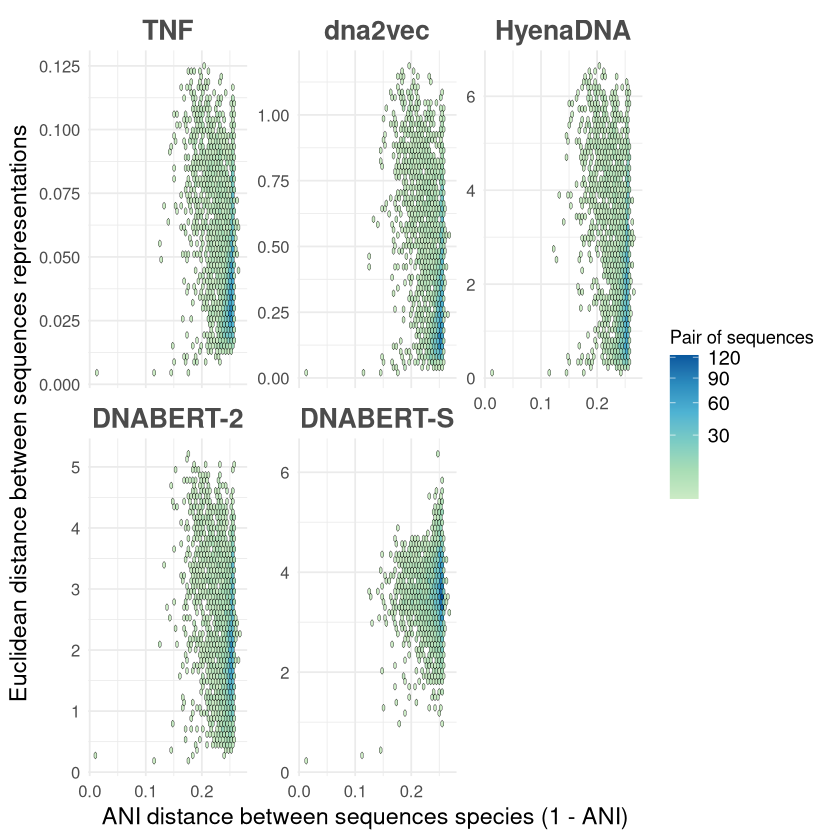

In [5]:
df_all$model <- factor(df_all$model, levels = c("tnf", "dna2vec", "hyenadna", "dnabert2", "dnaberts"))

p <- ggplot(df_all, aes(x = ani, y = emb)) +
  geom_hex(bins = 50, color = "black", linewidth = 0.1) +
  scale_fill_gradientn(
    colors = c("#CCEBC5", "#A8DDB5", "#7BCCC4", "#4EB3D3", "#2B8CBE", "#08589E"),
    trans = "sqrt"
  ) +
  labs(
    x = "ANI distance between sequences species (1 - ANI)",
    y = "Euclidean distance between sequences representations",
    fill = "Pair of sequences"
  ) +
  facet_wrap(~ model, nrow = 2, scales = "free_y",
             labeller = labeller(model = model_labels)) +
  theme_minimal() +
  theme(legend.position = "right", 
        legend.text = element_text(size = 12),
        strip.text = element_text(size = 16, face = "bold", colour = "#4b4b4b"),
        axis.text=element_text(size=10),
        axis.title=element_text(size=14))

p

In [6]:
ggsave(glue("../../Results/ani_vs_emb.png"), p, 
       width = 8, height = 6, dpi = 500)